In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

In [2]:
# 1. Veriyi Yükle
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00292/Wholesale%20customers%20data.csv"
df = pd.read_csv(url)

In [10]:
# 2. veriye ilk bakış
display(df.head())
df.describe()
df.info()
print(df.corr())


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


<class 'pandas.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB
                   Channel    Region     Fresh      Milk   Grocery    Frozen  \
Channel           1.000000  0.062028 -0.169172  0.460720  0.608792 -0.202046   
Region            0.062028  1.000000  0.055287  0.032288  0.007696 -0.021044   
Fresh            -0.169172  0.055287  1.000000  0.100510 -0.011854  0.345881   
Milk              0.460720  0.032288  0.100510  1.000000  0.728335  0.123994   
Grocery           

In [11]:
print(df.nunique())

Channel               2
Region                3
Fresh               433
Milk                421
Grocery             430
Frozen              426
Detergents_Paper    417
Delicassen          403
dtype: int64


BURADA 2 KATEGORİK DEĞİŞKENİMİZ VAR CHANNEL VE REGİON DOĞAL KÜMELEME YAPICAĞIM İÇİN BUNLARI ÇIKARICAM ÖNCELİKLE HEATMAP İLE KORALASYONLARA BAKALIM

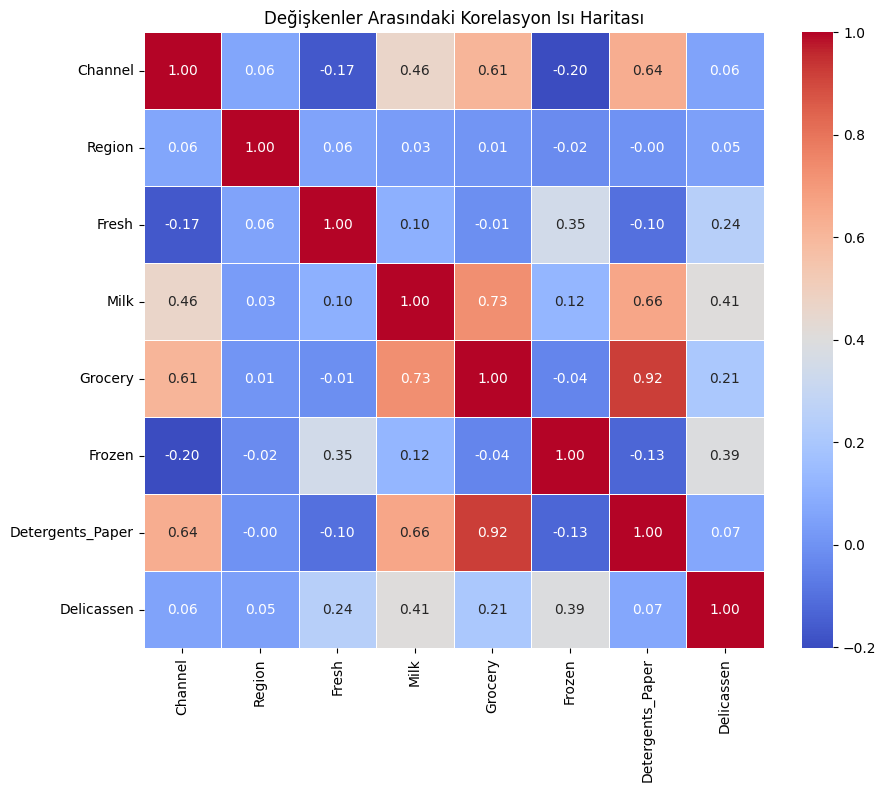

In [8]:
#korelasyonları ısıharitası ile gösteriyoruz
plt.figure(figsize=(10, 8))

sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)

plt.title("Değişkenler Arasındaki Korelasyon Isı Haritası")
plt.show()

VERİ SETİMİZ TEMİZ GÖZÜKMEKTE NULL DEĞERİMİZ YOK 
AMACIMIZ YALNIZCA HARCAMA KALEMLERİNE GÖRE KÜMELEME YAPMAK OLDUĞU İÇİN ŞİMDİ KATEGORİK DEĞİŞKENLERİ ÇIKARICAĞIM

In [12]:
data = df.drop(['Channel', 'Region'], axis=1)

In [13]:
#Ölçeklendirme (DBSCAN mesafe ölçtüğü için çok önemlidir)
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data)

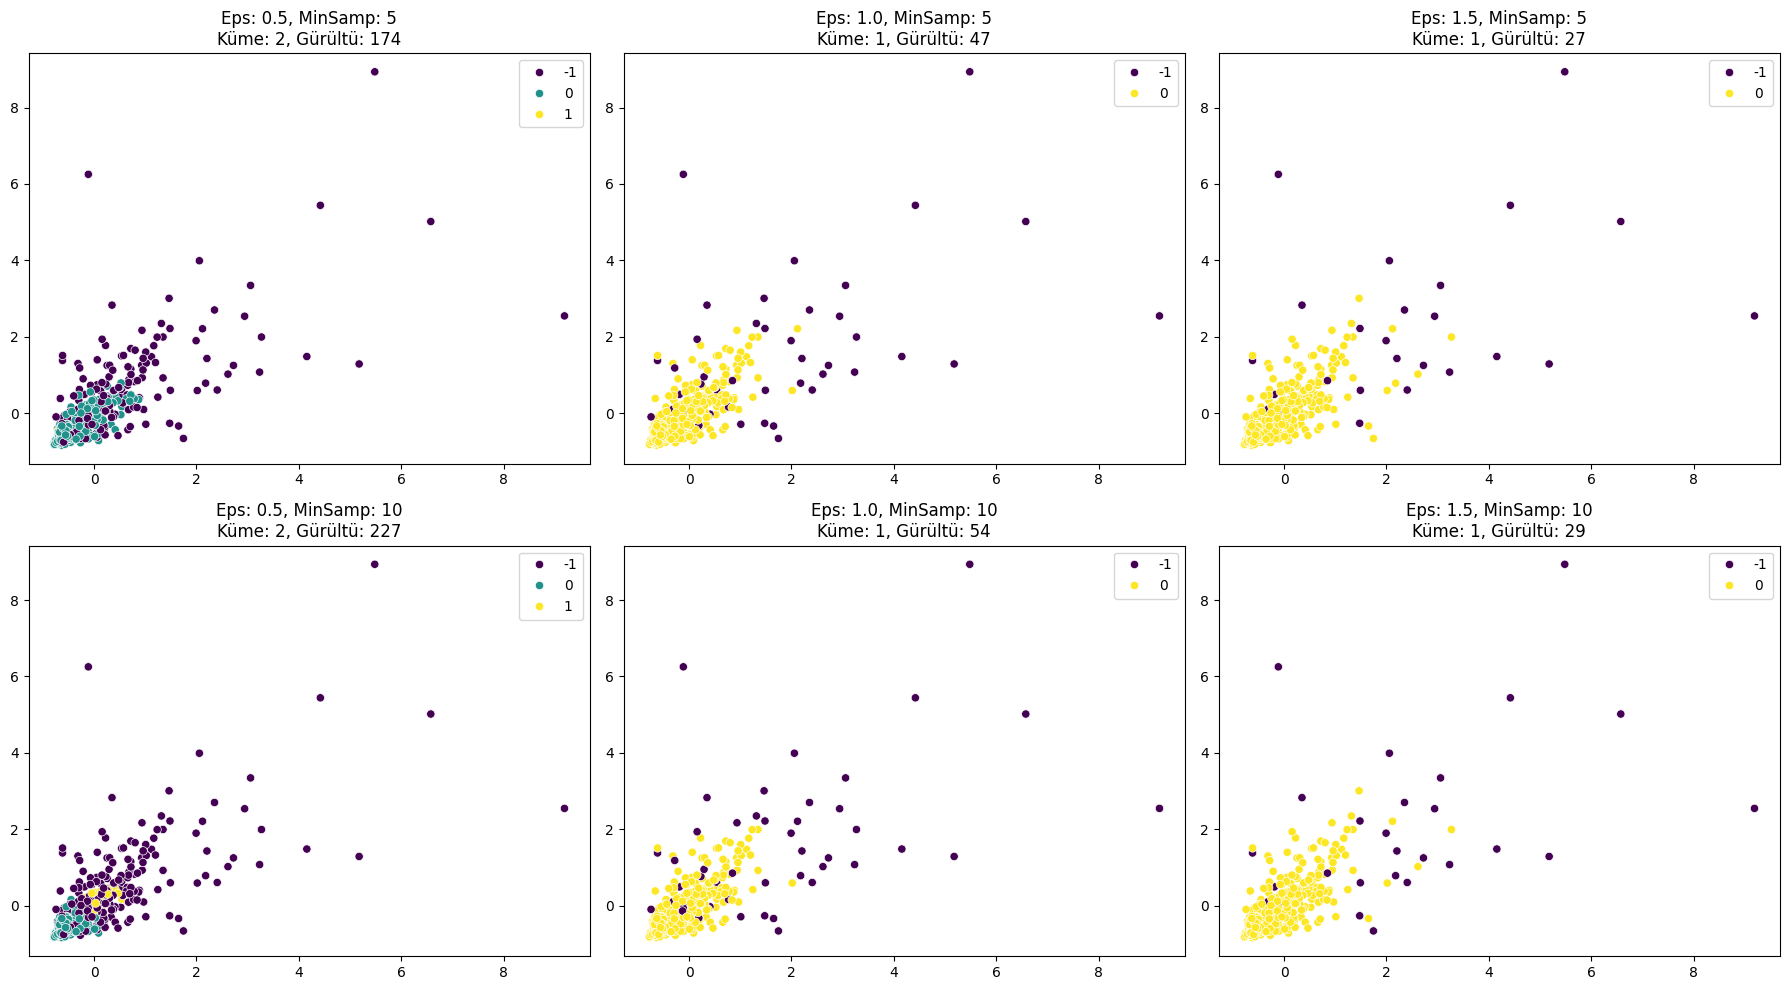

In [14]:
#Hiperparametreleri ayarlayacağız. Algoritma ile ilgili hiçbir bilgimiz olmasa dahi sklearn dokumantasyonlarından bakabiliyoruz. Baktığımızda görüğümüz iki önemli hiperparametre için denemeler yaptıracağız.
eps_values = [0.5, 1.0, 1.5]
min_samples_values = [5, 10]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, eps in enumerate(eps_values):
    for j, min_samples in enumerate(min_samples_values):
        idx = i + (j * 3)
        
        dbscan = DBSCAN(eps=eps, min_samples=min_samples)
        clusters = dbscan.fit_predict(data_scaled)
        
        # Görselleştirme (Harcama kalemlerinden ikisini seçiyoruz: Milk ve Grocery)
        sns.scatterplot(x=data_scaled[:, 1], y=data_scaled[:, 2], 
                        hue=clusters, palette='viridis', ax=axes[idx], legend='full')
        
        n_clusters = len(set(clusters)) - (1 if -1 in clusters else 0)
        n_noise = list(clusters).count(-1)
        
        axes[idx].set_title(f"Eps: {eps}, MinSamp: {min_samples}\nKüme: {n_clusters}, Gürültü: {n_noise}")

plt.tight_layout()
plt.show() 

DEĞERLENDİRME YAPTIĞIMIZDA EN İYİ HİPER PARAMETRELERİN EPS_VALUES = 1.5 İKEN MİNSAMP = 5,10 İKEN OLDUĞUNU GÖREBİLİYORUZ. EPSİLON DEĞERİ BİR NOKTANIN KOMŞUSU SAYILMASI İÇİN GEREKEN MAKSİMUM MESAFEYİ İFADE ETMEKTEDİR. ÖRNEKTE DE GÖRDÜĞÜMÜZ GİBİ ALGORİTMA EPSİLON DEĞERİ DÜŞTÜKÇE YANİ MESAFE AZALDIKÇA DAHA FAZLA KÜME ÜRETMEKTEDİR. MİN SAMPLE İSE DÜŞÜKKEN DAHA FAZLA KÜME OLUŞTURURLAR VE MİN SAMPLE ARTTIKÇA DAHA AZ KÜME OLUŞUR. MİN SAMPLE KÜME ÇEKİRDEĞİ OLUŞTURMASI İÇİN GEREKEN MİNİMUM NOKTA SAYISIDIR.